In [1]:
import torch
from pathlib import Path
from torch.utils.data import DataLoader
from ddpm.data.das_dataset import DasDataset
from ddpm.diffusion.rad_noise_scheduler import RADNoiseScheduler

**Model rad 1 : Earthquake Baseline 1001 :**

In [2]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files_earthquake = [das_data/"train_1001.h5"]
test_files_earthquake = [das_data/"test_1001.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_earthquake = DasDataset(train_files_earthquake)
test_set_earthquake = DasDataset(test_files_earthquake)
train_loader_earthquake = DataLoader(train_set_earthquake, batch_size=16, shuffle=True)
test_loader_earthquake = DataLoader(test_set_earthquake, batch_size=16, shuffle=False)

In [3]:
from ddpm.models.unet_rad import RAD
model_rad =  RAD(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)

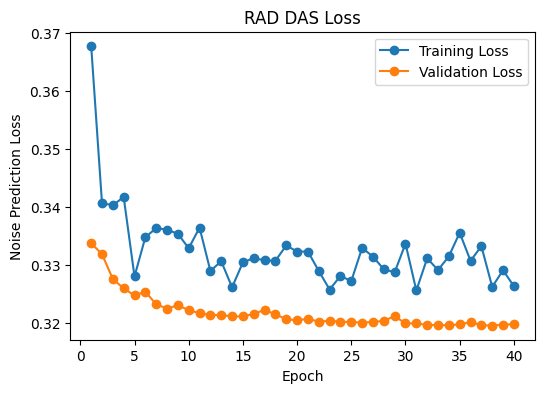

In [4]:
from ddpm.training.rad_training import train_rad
from ddpm.plotting.loss_plot import update_loss_plot

scheduler_rad = RADNoiseScheduler(ph1_steps=1000, ph2_steps=1000, beta_start=1e-4,beta_end=0.02, device=device)

checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)

model_path=checkpoints/"das_rad_earthquake_model.pth"
loss_plot_path=checkpoints/"das_rad_earthquake_loss.png"

optimizer_rad= torch.optim.Adam(model_rad.parameters(), lr=1e-4)

epochs= 40 
train_losses=[]
val_losses=[]
start_epoch=0

checkpoint_meta = {
    "base_channels": 64, "channels_multiplier": ( 1,1,2,2,4),
                  "normalization": {"function": "arcsinh", "s": 50.0, "A_max": 12350.0},
    "model_key" : "model_rad", "optimizer_key": "optimizer_rad", "train_loss_key": "train_losses",
    "val_loss_key": "val_losses"
}


if model_path.exists():
    checkpoint = torch.load(model_path,map_location=device)

    if "model_rad" in checkpoint:
        model_rad.load_state_dict(checkpoint["model_rad"])

    if "optimizer_rad" in checkpoint:
        optimizer_rad.load_state_dict(checkpoint["optimizer_rad"])

    train_losses= checkpoint.get("train_losses", [])
    val_losses= checkpoint.get("val_losses", [])
    start_epoch=checkpoint.get("completed_epochs", len(train_losses)) 

train_losses, val_losses = train_rad(
    model=model_rad,
    train_loader=train_loader_earthquake,
    val_loader=test_loader_earthquake,
    scheduler=scheduler_rad,
    optimizer=optimizer_rad,
    device=device,
    epochs=epochs,
    checkpoint_path=model_path,
    model_key="model_rad",
    optimizer_key="optimizer_rad",
    train_loss_key="train_losses",
    val_loss_key="val_losses",
    start_epoch=start_epoch,
    train_losses=train_losses,
    val_losses=val_losses,
    checkpoint_meta=checkpoint_meta,
    plot_function=update_loss_plot,
    loss_plot_path=loss_plot_path
)
   

In [5]:
from ddpm.diffusion.rddim import rddim_sample

samples_rad,masks_rad,saved_steps=rddim_sample(model=model_rad,scheduler=scheduler_rad,num_samples=2,num_steps=100,device=device,eta=0.0,timesteps_shown=[1999,1494,989,606,303,0])

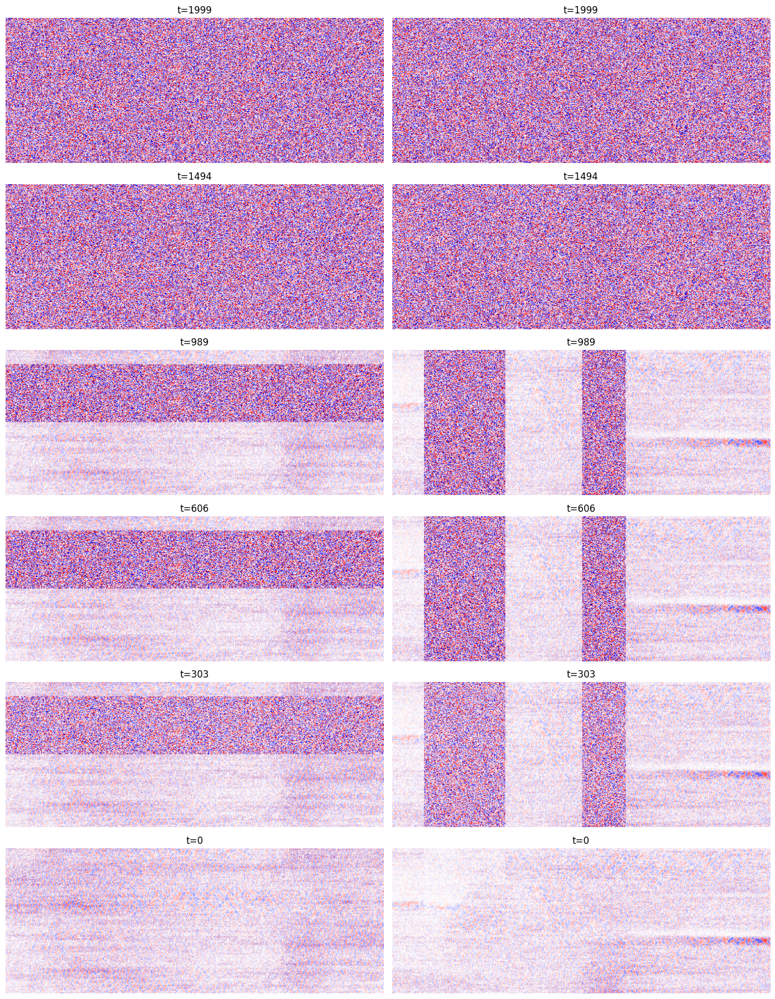

In [6]:
import matplotlib.pyplot as plt
import torch

steps=list(saved_steps.keys())

fig,axes=plt.subplots(len(steps),2,figsize=(14,3*len(steps)))
w=3.0 #torch.quantile(sample.abs(),0.99)
for row,step in enumerate(steps):
    for i in range(2):
        sample=saved_steps[step][i,0]
        #w=torch.quantile(sample.abs(),0.99)
        axes[row,i].imshow(sample,aspect="auto",cmap="seismic",vmin=-w,vmax=w)
        axes[row,i].axis("off")
        axes[row,i].set_title(f"t={step}")

plt.tight_layout()
plt.show()

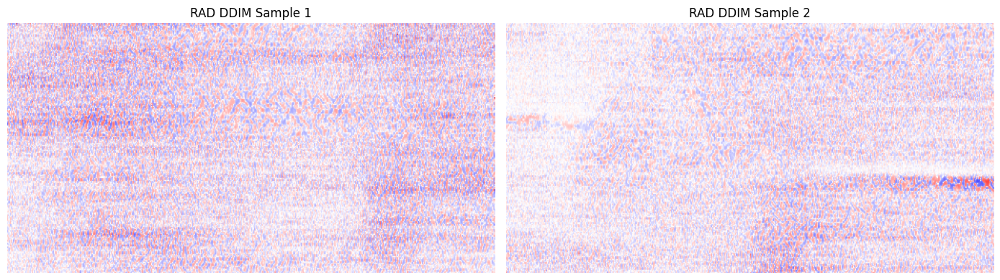

In [9]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14,4))

for i in range(2):
    sample = samples_rad[i, 0].detach().cpu()

    #w_min = torch.quantile(sample, 0.01)
    w_max = 3.0 #torch.quantile(sample, 0.99)

    axes[i].imshow(sample,aspect="auto",cmap="seismic",vmin=-w_max,vmax=w_max)

    axes[i].axis("off")
    axes[i].set_title(f"RAD DDIM Sample {i+1}")

plt.tight_layout()
plt.show()

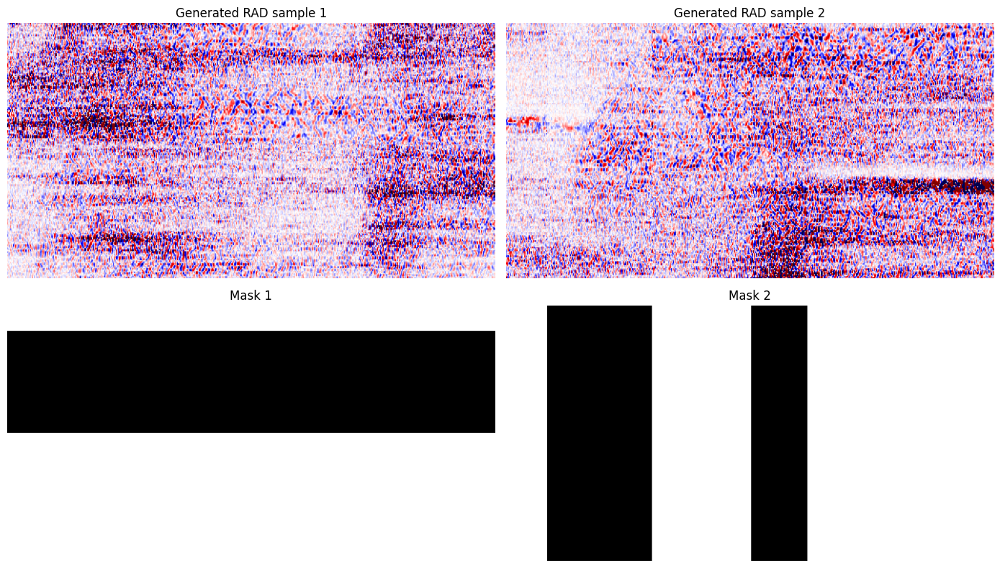

In [27]:
import matplotlib.pyplot as plt
import torch
from ddpm.utils.normalizer import denormalize

samples_denorm = denormalize(samples_rad)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for i in range(2):
    sample = samples_denorm[i, 0].detach().cpu()
    mask = masks_rad[i, 0].detach().cpu()

    #w_min = torch.quantile(sample, 0.01)
    #w_max = torch.quantile(sample, 0.99)
    w=torch.quantile(sample, 0.99)
   

    axes[0, i].imshow(sample,aspect="auto",cmap="seismic",vmin=-w,vmax=w)
    axes[0, i].axis("off")
    axes[0, i].set_title(f"Generated RAD sample {i+1}")

    axes[1, i].imshow(mask, aspect="auto", cmap="gray")
    axes[1, i].axis("off")
    axes[1, i].set_title(f"Mask {i+1}")

plt.tight_layout()
plt.show()

In [32]:
'''inference using only phase 1'''
from ddpm.diffusion.rad_inpainting import rad_inpaint
from ddpm.masks.rad_masks import random_rad_mask

x0=next(iter(test_loader_earthquake))[:2].to(device)

B,C,H,W=x0.shape
mask=random_rad_mask(B,H,W,device)

result_rad,x_start,saved_steps=rad_inpaint(model=model_rad,scheduler=scheduler_rad,x0=x0,mask=mask,device=device,timesteps_shown=[999,750,500,250,100,0])

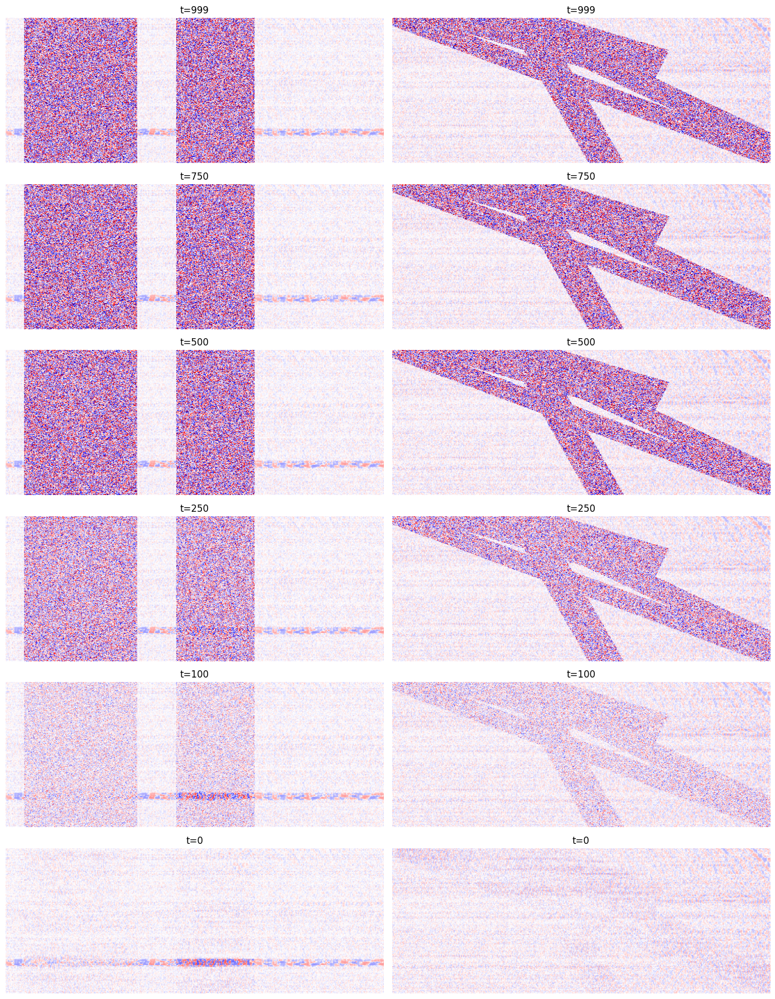

In [34]:
import matplotlib.pyplot as plt
import torch
from ddpm.utils.normalizer import denormalize

steps=list(saved_steps.keys())
fig,axes=plt.subplots(len(steps),2,figsize=(14,3*len(steps)))
w=3.0
for row,step in enumerate(steps):
    for i in range(2):
        sample=saved_steps[step][i,0].detach().cpu()
        #w=torch.quantile(sample.abs(),0.99)
        axes[row,i].imshow(sample,aspect="auto",cmap="seismic",vmin=-w,vmax=w)
        axes[row,i].axis("off")
        axes[row,i].set_title(f"t={step}")

plt.tight_layout()
plt.show()

In [35]:
from ddpm.utils.normalizer import denormalize

x0_denorm=denormalize(x0.detach().cpu())
result_denorm=denormalize(result_rad.detach().cpu())

In [37]:
from ddpm.diffusion.rddim import generate_rddim_samples

samples_rad_1024=generate_rddim_samples(
    model=model_rad,
    scheduler=scheduler_rad,
    num_samples=1024,
    batch_size=16,
    num_steps=100,
    device=device,
    eta=0.0,
    seed=42
)

RDDIM Samples: 100%|██████████| 64/64 [15:46<00:00, 14.79s/it, generated=1024]


In [38]:
torch.save(samples_rad_1024,"checkpoints/rad_rddim_1024.pt")

In [ ]:
import numpy as np
import torch
from ddpm.utils.normalizer import denormalize

num_eval=samples_rad_1024.shape[0]

real_samples=[]
for batch in test_loader_earthquake:
    real_samples.append(batch)

real_samples=torch.cat(real_samples,dim=0)[:num_eval]

real_denorm=denormalize(real_samples).detach().cpu().numpy()
rad_denorm=denormalize(samples_rad_1024).detach().cpu().numpy()

percentiles=[50,60,90,99,99.9,99.99]

real_percentiles=np.percentile(np.abs(real_denorm).reshape(-1),percentiles)
rad_percentiles=np.percentile(np.abs(rad_denorm).reshape(-1),percentiles)

for i in range(len(percentiles)):
    print(
        f"{percentiles[i]}% | "
        f"real DAS Earthquakes: {real_percentiles[i]:.2f} | "
        f"RAD generated: {rad_percentiles[i]:.2f}"
    )

50% | real DAS Earthquakes: 41.86 | RAD generated: 111.34
60% | real DAS Earthquakes: 55.94 | RAD generated: 147.76
90% | real DAS Earthquakes: 248.72 | RAD generated: 431.33
99% | real DAS Earthquakes: 1229.64 | RAD generated: 1330.10
99.9% | real DAS Earthquakes: 2891.07 | RAD generated: 3335.22
99.99% | real DAS Earthquakes: 5326.53 | RAD generated: 8551.68


In [41]:
real_denorm64=real_denorm.astype(np.float64)
rad_denorm64=rad_denorm.astype(np.float64)

real_rms=np.sqrt(np.mean(real_denorm64**2,axis=(1,2,3)))
rad_rms=np.sqrt(np.mean(rad_denorm64**2,axis=(1,2,3)))

print("Real RMS mean:",real_rms.mean())
print("RAD RMS mean:",rad_rms.mean())
print("Real RMS median:",np.median(real_rms))
print("RAD RMS median:",np.median(rad_rms))

Real RMS mean: 173.3407747863019
RAD RMS mean: inf
Real RMS median: 79.12012366505375
RAD RMS median: 1070.262367853107


In [42]:
print("Real max abs:",np.max(np.abs(real_denorm64)))
print("RAD max abs:",np.max(np.abs(rad_denorm64)))

Real max abs: 19360.994140625
RAD max abs: inf


In [43]:
print("RAD normalized finite:",torch.isfinite(samples_rad_1024).all())
print("RAD normalized min:",samples_rad_1024.min().item())
print("RAD normalized max:",samples_rad_1024.max().item())
print("RAD normalized max abs:",samples_rad_1024.abs().max().item())

RAD normalized finite: tensor(True)
RAD normalized min: -32.9226188659668
RAD normalized max: 37.943939208984375
RAD normalized max abs: 37.943939208984375


In [44]:
real_norm=real_samples.detach().cpu()

print("Real normalized min:",real_norm.min().item())
print("Real normalized max:",real_norm.max().item())
print("Real normalized max abs:",real_norm.abs().max().item())

print("RAD normalized min:",samples_rad_1024.min().item())
print("RAD normalized max:",samples_rad_1024.max().item())
print("RAD normalized max abs:",samples_rad_1024.abs().max().item())

Real normalized min: -1.0520323514938354
Real normalized max: 1.0724867582321167
Real normalized max abs: 1.0724867582321167
RAD normalized min: -32.9226188659668
RAD normalized max: 37.943939208984375
RAD normalized max abs: 37.943939208984375


In [45]:
real_norm_np=real_samples.detach().cpu().numpy()
rad_norm_np=samples_rad_1024.detach().cpu().numpy()

percentiles=[50,90,99,99.9,99.99]

real_norm_percentiles=np.percentile(np.abs(real_norm_np).reshape(-1),percentiles)
rad_norm_percentiles=np.percentile(np.abs(rad_norm_np).reshape(-1),percentiles)

for i in range(len(percentiles)):
    print(
        f"{percentiles[i]}% | "
        f"real normalized: {real_norm_percentiles[i]:.4f} | "
        f"RAD normalized: {rad_norm_percentiles[i]:.4f}"
    )

50% | real normalized: 0.1228 | RAD normalized: 0.2484
90% | real normalized: 0.3720 | RAD normalized: 0.4597
99% | real normalized: 0.6281 | RAD normalized: 0.6408
99.9% | real normalized: 0.7659 | RAD normalized: 0.7889
99.99% | real normalized: 0.8644 | RAD normalized: 0.9407


In [46]:
rad_abs=samples_rad_1024.abs()

print("> 1:",(rad_abs > 1).sum().item())
print("> 2:",(rad_abs > 2).sum().item())
print("> 5:",(rad_abs > 5).sum().item())
print("> 10:",(rad_abs > 10).sum().item())
print("> 20:",(rad_abs > 20).sum().item())

> 1: 6477
> 2: 551
> 5: 135
> 10: 47
> 20: 12


In [47]:
total=rad_abs.numel()

for threshold in [1,2,5,10,20]:
    count=(rad_abs > threshold).sum().item()
    print(
        f"> {threshold}: {count} pixels "
        f"({100*count/total:.6f}%)"
    )

> 1: 6477 pixels (0.004826%)
> 2: 551 pixels (0.000411%)
> 5: 135 pixels (0.000101%)
> 10: 47 pixels (0.000035%)
> 20: 12 pixels (0.000009%)


In [48]:
max_per_sample=samples_rad_1024.abs().amax(dim=(1,2,3))

worst_indices=torch.argsort(max_per_sample,descending=True)[:10]

print("Worst sample indices:",worst_indices)
print("Worst sample maxima:",max_per_sample[worst_indices])

print("Number of samples with max > 2:",(max_per_sample > 2).sum().item())
print("Number of samples with max > 5:",(max_per_sample > 5).sum().item())
print("Number of samples with max > 10:",(max_per_sample > 10).sum().item())

Worst sample indices: tensor([658, 317, 653, 929, 151, 712, 330, 700, 403, 197])
Worst sample maxima: tensor([37.9439, 34.5886, 32.9226, 29.7789, 28.3492, 25.4783, 24.5582, 22.5493,
        21.3844, 21.2648])
Number of samples with max > 2: 363
Number of samples with max > 5: 115
Number of samples with max > 10: 42


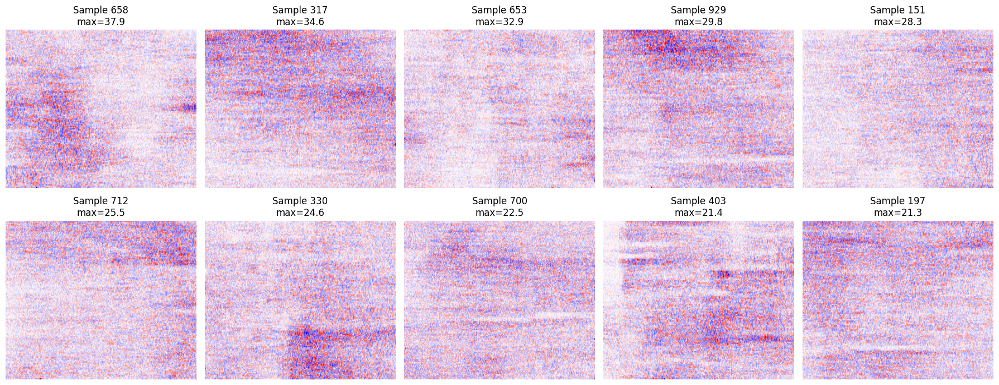

In [59]:
import matplotlib.pyplot as plt

fig,axes=plt.subplots(2,5,figsize=(18,7))

for i,idx in enumerate(worst_indices):
    sample=samples_rad_1024[idx,0].detach().cpu()

    axes.flat[i].imshow(sample,aspect="auto",cmap="seismic",vmin=-2,vmax=2)
    axes.flat[i].axis("off")
    axes.flat[i].set_title(f"Sample {idx.item()}\nmax={max_per_sample[idx]:.1f}")

plt.tight_layout()
plt.show()

In [50]:
sample_idx=worst_indices[0]

sample=samples_rad_1024[sample_idx,0]
max_position=torch.nonzero(sample.abs() == sample.abs().max(),as_tuple=False)

print("Sample:",sample_idx.item())
print("Maximum:",sample.abs().max().item())
print("Position:",max_position)

Sample: 658
Maximum: 37.943939208984375
Position: tensor([[255,  83]])


In [ ]:
for idx in worst_indices:
    sample=samples_rad_1024[idx,0]

    position=torch.nonzero(sample.abs() == sample.abs().max(),as_tuple=False)[0]
    print(
        f"Sample {idx.item()} | "
        f"max={sample.abs().max().item():.2f} | "
        f"position={position.tolist()}"
    )

Sample 658 | max=37.94 | position=[255, 83]
Sample 317 | max=34.59 | position=[186, 511]
Sample 653 | max=32.92 | position=[255, 397]
Sample 929 | max=29.78 | position=[255, 130]
Sample 151 | max=28.35 | position=[255, 503]
Sample 712 | max=25.48 | position=[255, 93]
Sample 330 | max=24.56 | position=[238, 0]
Sample 700 | max=22.55 | position=[255, 511]
Sample 403 | max=21.38 | position=[255, 297]
Sample 197 | max=21.26 | position=[0, 301]


In [ ]:
max_positions=[]

for i in range(samples_rad_1024.shape[0]):
    sample=samples_rad_1024[i,0]

    position=torch.nonzero(sample.abs() == sample.abs().max(),as_tuple=False)[0]
    max_positions.append(position)

max_positions=torch.stack(max_positions)

rows=max_positions[:,0]
cols=max_positions[:,1]

border=((rows == 0) |(rows == 255) |(cols == 0) |(cols == 511))

print("Maxima on image border:",border.sum().item())
print("Percentage:",100*border.float().mean().item())

Maxima on image border: 738
Percentage: 72.0703125


In [55]:
import torch
import matplotlib.pyplot as plt

real_fk_samples=[]
rad_fk_samples=[]
num_eval=min(real_samples.shape[0],samples_rad_1024.shape[0])

for i in range(num_eval):

    real_sample=real_samples[i,0]
    rad_sample=samples_rad_1024[i,0]

    real_fk=torch.fft.fftshift(torch.fft.fft2(real_sample))
    rad_fk=torch.fft.fftshift(torch.fft.fft2(rad_sample))

    real_power=torch.log1p(torch.abs(real_fk)**2)
    rad_power=torch.log1p(torch.abs(rad_fk)**2)

    real_fk_samples.append(real_power)
    rad_fk_samples.append(rad_power)

real_fk_samples=torch.stack(real_fk_samples)
rad_fk_samples=torch.stack(rad_fk_samples)

real_fk_median=torch.median(real_fk_samples,dim=0).values
rad_fk_median=torch.median(rad_fk_samples,dim=0).values

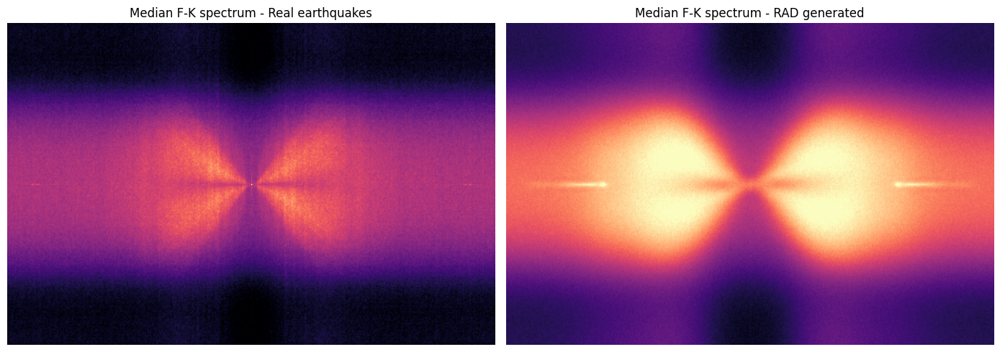

In [ ]:
all_fk=torch.cat([
    real_fk_median.flatten(),
    rad_fk_median.flatten()
])

vmin=torch.quantile(all_fk,0.01).item()
vmax=torch.quantile(all_fk,0.99).item()

fig,axes=plt.subplots(1,2,figsize=(14,5))

axes[0].imshow(real_fk_median.cpu(),aspect="auto",cmap="magma",vmin=vmin,vmax=vmax)
axes[0].set_title("Median F-K spectrum - Real earthquakes")
axes[0].axis("off")

axes[1].imshow(rad_fk_median.cpu(),aspect="auto",cmap="magma",vmin=vmin,vmax=vmax)
axes[1].set_title("Median F-K spectrum - RAD generated")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [67]:
samples_100=generate_rddim_samples(
    model=model_rad,
    scheduler=scheduler_rad,
    num_samples=32,
    batch_size=4,
    num_steps=100,
    device=device,
    eta=0.0,
    seed=42
)

samples_200=generate_rddim_samples(
    model=model_rad,
    scheduler=scheduler_rad,
    num_samples=32,
    batch_size=4,
    num_steps=200,
    device=device,
    eta=0.0,
    seed=42
)

samples_500=generate_rddim_samples(
    model=model_rad,
    scheduler=scheduler_rad,
    num_samples=32,
    batch_size=4,
    num_steps=500,
    device=device,
    eta=0.0,
    seed=42
)

RDDIM Samples: 100%|██████████| 8/8 [02:37<00:00, 19.71s/it, generated=32]


In [69]:
from ddpm.diffusion.rad_inpainting import rad_inpaint
from ddpm.masks.rad_masks import random_rad_mask

x0 = next(iter(test_loader_earthquake))[:20].to(device)

B, C, H, W = x0.shape
mask = random_rad_mask(B, H, W, device)

result_rad1, x_start1, saved_steps1 = rad_inpaint(
    model=model_rad,
    scheduler=scheduler_rad,
    x0=x0,
    mask=mask,
    device=device,
    timesteps_shown=[999, 750, 500, 250, 100, 0]
)

In [75]:
import numpy as np
import torch
from ddpm.utils.normalizer import denormalize

x0_denorm = denormalize(x0.detach().cpu())
result_denorm = denormalize(result_rad1.detach().cpu())

mask_cpu = mask.detach().cpu()

In [76]:
percentiles = [50, 60, 90, 99, 99.9, 99.99]

real_all = x0_denorm.numpy()
rad_all = result_denorm.numpy()

real_percentiles = np.percentile(np.abs(real_all).reshape(-1), percentiles)
rad_percentiles  = np.percentile(np.abs(rad_all).reshape(-1), percentiles)

for i in range(len(percentiles)):
    print(
        f"{percentiles[i]}% | "
        f"real earthquake: {real_percentiles[i]:.2f} | "
        f"RAD inpainted: {rad_percentiles[i]:.2f}"
    )

50% | real earthquake: 42.90 | RAD inpainted: 50.79
60% | real earthquake: 57.28 | RAD inpainted: 68.51
90% | real earthquake: 322.23 | RAD inpainted: 395.20
99% | real earthquake: 1988.88 | RAD inpainted: 2092.23
99.9% | real earthquake: 4060.61 | RAD inpainted: 4111.39
99.99% | real earthquake: 8318.78 | RAD inpainted: 7881.04


In [77]:
masked_pixels=(mask_cpu == 0)

real_masked=x0_denorm[masked_pixels].numpy()
rad_masked=result_denorm[masked_pixels].numpy()

real_masked_percentiles=np.percentile(np.abs(real_masked),percentiles)
rad_masked_percentiles=np.percentile(np.abs(rad_masked),percentiles)

for i in range(len(percentiles)):
    print(
        f"{percentiles[i]}% | "
        f"real masked: {real_masked_percentiles[i]:.2f} | "
        f"RAD inpainted: {rad_masked_percentiles[i]:.2f}"
    )

50% | real masked: 41.59 | RAD inpainted: 59.21
60% | real masked: 55.22 | RAD inpainted: 79.83
90% | real masked: 268.96 | RAD inpainted: 402.40
99% | real masked: 1647.64 | RAD inpainted: 1926.03
99.9% | real masked: 4055.00 | RAD inpainted: 4198.53
99.99% | real masked: 8754.54 | RAD inpainted: 8187.39


In [5]:
import importlib
import ddpm.diffusion.rddim2 as rddim2
importlib.reload(rddim2)  

from ddpm.diffusion.rddim2 import rddim_sample as rddim_sample2
from ddpm.diffusion.rddim2 import generate_rddim_samples as generate_rddim_samples2

In [6]:
def border_stats(samples):
    a=samples[:,0].abs()
    N,H,W=a.shape
    flat=a.flatten(1).argmax(dim=1)
    rows,cols=flat//W,flat%W
    border=(rows==0)|(rows==H-1)|(cols==0)|(cols==W-1)
    return {
        "border maxima %":round(100*border.float().mean().item(),2),
        "top":(rows==0).sum().item(),
        "bottom":(rows==H-1).sum().item(),
        "left":(cols==0).sum().item(),
        "right":(cols==W-1).sum().item(),
        "max abs":round(a.max().item(),3),
        "samples with max > 1.1":(a.amax(dim=(1,2))>1.1).sum().item(),
    }

In [7]:
samples_noclip=generate_rddim_samples2(model=model_rad,scheduler=scheduler_rad,num_samples=32,batch_size=4,
                                      num_steps=100,device=device,eta=0.0,seed=42,clip_x0=None)

samples_clip=generate_rddim_samples2(model=model_rad,scheduler=scheduler_rad,num_samples=32,batch_size=4,
                                    num_steps=100,device=device,eta=0.0,seed=42,clip_x0=1.1)

print("No clip:",border_stats(samples_noclip))
print("Clip 1.1:",border_stats(samples_clip))

RDDIM Samples: 100%|██████████| 8/8 [00:31<00:00,  3.95s/it, generated=32]

No clip: {'border maxima %': 84.38, 'top': 7, 'bottom': 9, 'left': 2, 'right': 10, 'max abs': 12.773, 'samples with max > 1.1': 25}
Clip 1.1: {'border maxima %': 25.0, 'top': 1, 'bottom': 2, 'left': 2, 'right': 3, 'max abs': 1.1, 'samples with max > 1.1': 0}


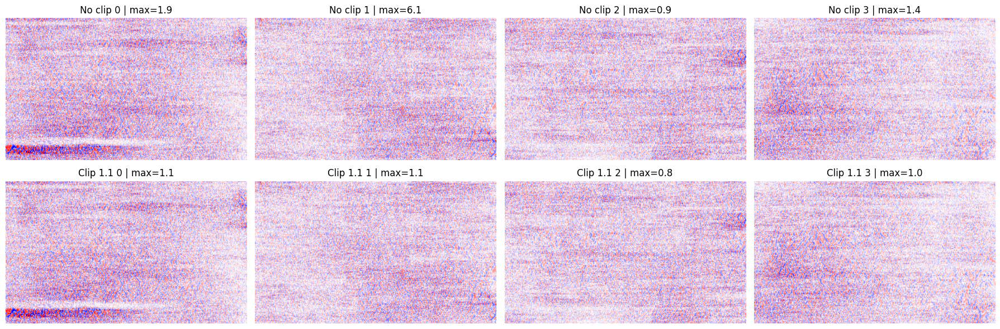

In [8]:
import matplotlib.pyplot as plt

fig,axes=plt.subplots(2,4,figsize=(18,6))
for i in range(4):
    axes[0,i].imshow(samples_noclip[i,0],aspect="auto",cmap="seismic",vmin=-2,vmax=2)
    axes[0,i].set_title(f"No clip {i} | max={samples_noclip[i].abs().max():.1f}")
    axes[1,i].imshow(samples_clip[i,0],aspect="auto",cmap="seismic",vmin=-2,vmax=2)
    axes[1,i].set_title(f"Clip 1.1 {i} | max={samples_clip[i].abs().max():.1f}")
for ax in axes.flat: ax.axis("off")
plt.tight_layout()
plt.show()

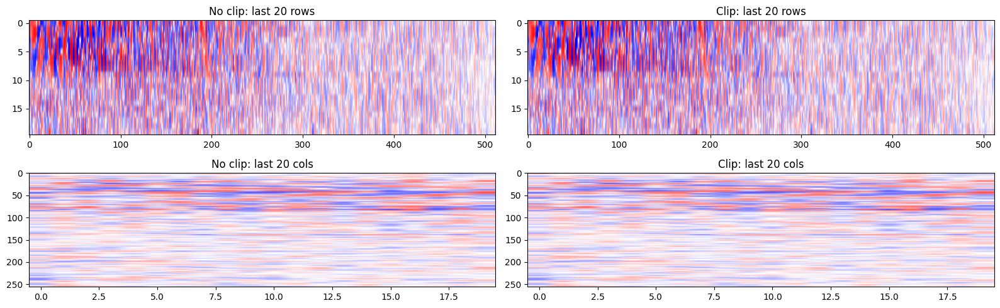

In [9]:
fig,axes=plt.subplots(2,2,figsize=(16,5))
idx=0
axes[0,0].imshow(samples_noclip[idx,0,-20:,:],aspect="auto",cmap="seismic",vmin=-2,vmax=2); axes[0,0].set_title("No clip: last 20 rows")
axes[0,1].imshow(samples_clip[idx,0,-20:,:],aspect="auto",cmap="seismic",vmin=-2,vmax=2);   axes[0,1].set_title("Clip: last 20 rows")
axes[1,0].imshow(samples_noclip[idx,0,:,-20:],aspect="auto",cmap="seismic",vmin=-2,vmax=2); axes[1,0].set_title("No clip: last 20 cols")
axes[1,1].imshow(samples_clip[idx,0,:,-20:],aspect="auto",cmap="seismic",vmin=-2,vmax=2);   axes[1,1].set_title("Clip: last 20 cols")
plt.tight_layout()
plt.show()

In [11]:
real_samples=torch.cat([batch for batch in test_loader_earthquake],dim=0)
def saturation_stats(samples,clip=1.1,tol=0.01):
    a=samples[:,0].abs()
    N,H,W=a.shape
    sat=a>=clip-tol
    border=torch.zeros(H,W,dtype=torch.bool); border[0,:]=border[-1,:]=border[:,0]=border[:,-1]=True
    n_sat=sat.sum().item()
    return {
        "saturated pixels":n_sat,
        "saturated %":round(100*n_sat/a.numel(),5),
        "samples with any saturation":sat.any(dim=(1,2)).sum().item(),
        "saturated on border %":round(100*sat[:,border].sum().item()/max(n_sat,1),2),
        "saturated in last 4 rows %":round(100*sat[:,-4:,:].sum().item()/max(n_sat,1),2),
    }

real_32=real_samples[:32]
print("Real border:",border_stats(real_32))
print("Clip saturation:",saturation_stats(samples_clip))

Real border: {'border maxima %': 3.12, 'top': 0, 'bottom': 0, 'left': 1, 'right': 0, 'max abs': 1.072, 'samples with max > 1.1': 0}
Clip saturation: {'saturated pixels': 16, 'saturated %': 0.00038, 'samples with any saturation': 8, 'saturated on border %': 25.0, 'saturated in last 4 rows %': 6.25}


In [12]:
def edge_profile(samples,k=4):
    a=samples[:,0].abs().double()
    row=a.mean(dim=(0,2)); col=a.mean(dim=(0,1))
    ref_r,ref_c=row[k:-k].median(),col[k:-k].median()
    return {
        "top":[round(v,2) for v in (row[:k]/ref_r).tolist()],
        "bottom":[round(v,2) for v in (row[-k:]/ref_r).tolist()],
        "left":[round(v,2) for v in (col[:k]/ref_c).tolist()],
        "right":[round(v,2) for v in (col[-k:]/ref_c).tolist()],
    }

print("Real:",edge_profile(real_samples))
print("Clip:",edge_profile(samples_clip))

Real: {'top': [1.0, 1.01, 1.0, 1.01], 'bottom': [1.0, 1.0, 1.0, 1.0], 'left': [0.87, 0.87, 0.87, 0.87], 'right': [1.14, 1.15, 1.14, 1.14]}
Clip: {'top': [0.95, 0.97, 0.98, 1.01], 'bottom': [0.9, 0.88, 0.86, 0.85], 'left': [0.82, 0.81, 0.83, 0.82], 'right': [0.97, 0.94, 0.95, 0.93]}


In [13]:
samples_rad_1024_clip=generate_rddim_samples2(model=model_rad,scheduler=scheduler_rad,num_samples=1024,batch_size=16,
                                             num_steps=100,device=device,eta=0.0,seed=42,clip_x0=1.1)
torch.save(samples_rad_1024_clip,"checkpoints/rad_rddim_1024_clip.pt")

print(border_stats(samples_rad_1024_clip))

import numpy as np
from ddpm.utils.normalizer import denormalize

rad_denorm_clip=denormalize(samples_rad_1024_clip).detach().cpu().numpy().astype(np.float64)
real_denorm64=denormalize(real_samples).detach().cpu().numpy().astype(np.float64)

for p in [50,60,90,99,99.9,99.99]:
    print(f"{p}% | real: {np.percentile(np.abs(real_denorm64),p):.2f} | RAD clip: {np.percentile(np.abs(rad_denorm_clip),p):.2f}")

print("Real RMS median:",np.median(np.sqrt(np.mean(real_denorm64**2,axis=(1,2,3)))))
print("RAD clip RMS median:",np.median(np.sqrt(np.mean(rad_denorm_clip**2,axis=(1,2,3)))))
print("RAD clip max abs:",np.max(np.abs(rad_denorm_clip)))

RDDIM Samples: 100%|██████████| 64/64 [15:47<00:00, 14.80s/it, generated=1024]


{'border maxima %': 21.09, 'top': 44, 'bottom': 56, 'left': 21, 'right': 101, 'max abs': 1.1, 'samples with max > 1.1': 0}
50% | real: 41.86 | RAD clip: 107.48
60% | real: 55.94 | RAD clip: 142.40
90% | real: 248.72 | RAD clip: 411.63
99% | real: 1229.64 | RAD clip: 1252.33
99.9% | real: 2891.07 | RAD clip: 3082.34
99.99% | real: 5326.53 | RAD clip: 7219.19
Real RMS median: 79.12012366505375
RAD clip RMS median: 293.439223247914
RAD clip max abs: 22963.65625


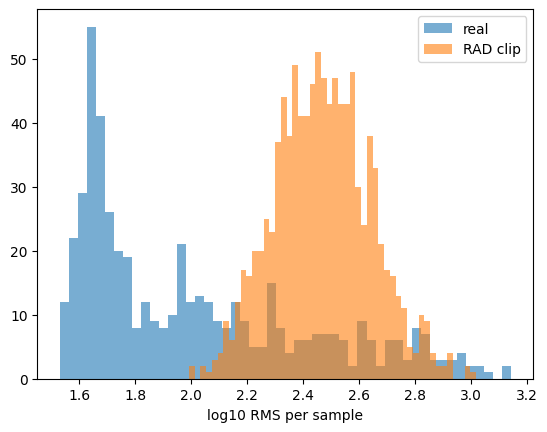

In [14]:
import matplotlib.pyplot as plt
real_rms=np.sqrt(np.mean(real_denorm64**2,axis=(1,2,3)))
rad_rms=np.sqrt(np.mean(rad_denorm_clip**2,axis=(1,2,3)))
plt.hist(np.log10(real_rms),bins=50,alpha=0.6,label="real")
plt.hist(np.log10(rad_rms),bins=50,alpha=0.6,label="RAD clip")
plt.xlabel("log10 RMS per sample"); plt.legend(); plt.show()

In [15]:
from ddpm.diffusion.rad_inpainting import rad_inpaint
from ddpm.masks.rad_masks import random_rad_mask

x0=next(iter(test_loader_earthquake)).to(device)
B,C,H,W=x0.shape
g=torch.Generator(device=device).manual_seed(0)
mask=random_rad_mask(B,H,W,device,generator=g)
result,_,_=rad_inpaint(model=model_rad,scheduler=scheduler_rad,x0=x0,mask=mask,device=device,timesteps_shown=[])

hole=(mask==0).cpu()
real_hole=x0.cpu()[hole].abs().numpy()
gen_hole=result.cpu()[hole].abs().numpy()
for p in [50,90,99,99.9]:
    print(f"{p}% | true: {np.percentile(real_hole,p):.4f} | inpainted: {np.percentile(gen_hole,p):.4f}")

50% | true: 0.1255 | inpainted: 0.1574
90% | true: 0.4111 | inpainted: 0.4467
99% | true: 0.6875 | inpainted: 0.7442
99.9% | true: 0.8001 | inpainted: 0.8769


known region changed by: 0.0


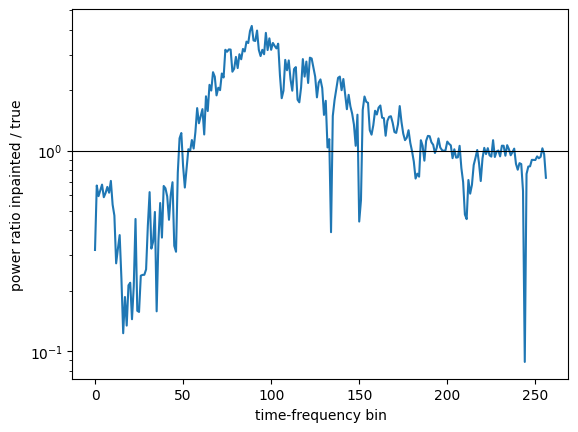

In [ ]:
from ddpm.masks.rad_masks import channel_strip

x0=next(iter(test_loader_earthquake)).to(device)
B,C,H,W=x0.shape
g=torch.Generator(device=device).manual_seed(0)
mask=channel_strip(B,H,W,device,generator=g)
result,_,_=rad_inpaint(model=model_rad,scheduler=scheduler_rad,x0=x0,mask=mask,device=device,timesteps_shown=[])

print("known region changed by:",(result-x0)[mask==1].abs().max().item())  

rows=(mask[:,0,:,0]==0)
true_rows=x0[:,0][rows].cpu()
gen_rows=result[:,0][rows].cpu()
psd_true=(torch.fft.rfft(true_rows,dim=-1).abs()**2).mean(0)
psd_gen=(torch.fft.rfft(gen_rows,dim=-1).abs()**2).mean(0)

plt.semilogy(psd_gen/psd_true)
plt.axhline(1,color="k",lw=0.8)
plt.xlabel("time-frequency bin"); plt.ylabel("power ratio inpainted / true")
plt.show()

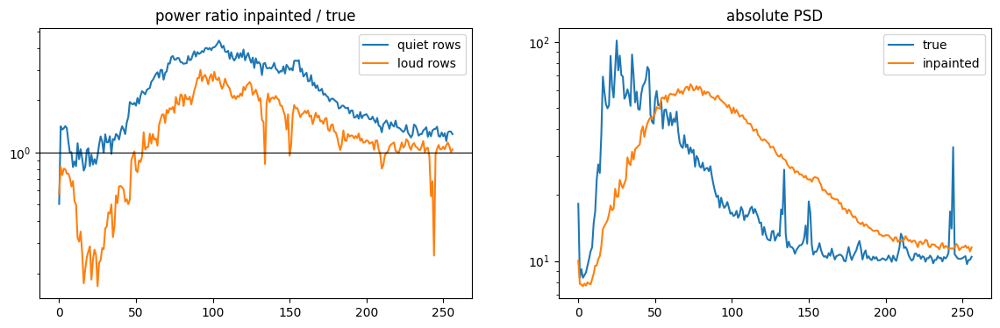

quiet RMS ratio: 1.5055267810821533
loud RMS ratio: 1.0329779386520386


In [17]:
from ddpm.masks.rad_masks import channel_strip
from ddpm.diffusion.rad_inpainting import rad_inpaint

def collect_hole_rows(model,loader,n_batches=6,seed=0):
    g=torch.Generator(device=device).manual_seed(seed)
    T=[];G=[]
    for k,batch in enumerate(loader):
        if k>=n_batches: break
        x0=batch.to(device); B,C,H,W=x0.shape
        mask=channel_strip(B,H,W,device,generator=g)
        res,_,_=rad_inpaint(model=model,scheduler=scheduler_rad,x0=x0,mask=mask,device=device,generator=g)
        rows=(mask[:,0,:,0]==0)
        T.append(x0[:,0][rows].cpu()); G.append(res[:,0][rows].cpu())
    return torch.cat(T),torch.cat(G)

T,G=collect_hole_rows(model_rad,test_loader_earthquake)

def psd(x): return (torch.fft.rfft(x,dim=-1).abs()**2).mean(0)
rms=T.pow(2).mean(-1).sqrt()
quiet=rms<rms.median()

fig,axes=plt.subplots(1,2,figsize=(14,4))
for name,sel in [("quiet rows",quiet),("loud rows",~quiet)]:
    axes[0].semilogy(psd(G[sel])/psd(T[sel]),label=name)
axes[0].axhline(1,color="k",lw=0.8); axes[0].legend(); axes[0].set_title("power ratio inpainted / true")
axes[1].semilogy(psd(T),label="true"); axes[1].semilogy(psd(G),label="inpainted"); axes[1].legend(); axes[1].set_title("absolute PSD")
plt.show()

for name,sel in [("quiet",quiet),("loud",~quiet)]:
    print(name,"RMS ratio:",(G[sel].pow(2).mean().sqrt()/T[sel].pow(2).mean().sqrt()).item())

In [18]:
def band_ratios(T,G,sel):
    pt,pg=psd(T[sel]),psd(G[sel])
    bands={"tief 0-45":slice(0,46),"mittel 50-140":slice(50,141),"hoch 150-256":slice(150,257)}
    out={name:round((pg[b].sum()/pt[b].sum()).item(),2) for name,b in bands.items()}
    out["RMS"]=round((G[sel].pow(2).mean().sqrt()/T[sel].pow(2).mean().sqrt()).item(),2)
    return out

print("ruhig:",band_ratios(T,G,quiet))
print("laut:",band_ratios(T,G,~quiet))

ruhig: {'tief 0-45': 1.09, 'mittel 50-140': 3.3, 'hoch 150-256': 1.77, 'RMS': 1.51}
laut: {'tief 0-45': 0.37, 'mittel 50-140': 1.73, 'hoch 150-256': 1.18, 'RMS': 1.03}
